# Feature-Report Donor Modeling

This notebook predicts whether a constituent will cross the synthetic **$1,200 annual recognition-credit threshold in the following fiscal year**. It implements the feature specification in `docs/feature_report.pdf` rather than the earlier program-adoption target.

The modeling row is `(constituent_id, observation_fiscal_year)`. Features use information available through the observation year; the target uses recognition-credit giving in the next year. Direct payment revenue and soft-credit recognition remain separate.

## 1. Scope and leakage controls

- Exact duplicate soft-credit rows are removed before aggregation.
- Legacy payment rows use `constituent_id_1` only; unpivoting all household IDs would duplicate one gift.
- The target is attached only after historical features are constructed.
- Raw identifiers, next-year activity, and cultivation treatment/outcome fields are excluded from predictors.
- The latest observation year is an untouched time-based holdout.

The data are synthetic. Results validate this workflow and the generator, not conclusions about real PBS Utah donors.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
TARGET = 'target_next_fy_1200'
PROJECT = Path.cwd()
if not (PROJECT / 'tables').exists():
    PROJECT = Path(r'C:\Users\msdor\donor_prediction_capstone_project')
TABLES = PROJECT / 'tables'
OUTPUTS = PROJECT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)
print(f'Project: {PROJECT}')
print(f'Tables available: {TABLES.exists()}')

Project: c:\Users\msdor\donor_prediction_capstone_project
Tables available: True


## 2. Load and standardize source tables

In [2]:
def snake_case(columns):
    return (columns.astype(str).str.strip().str.lower()
            .str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))

def load_table(filename):
    path = TABLES / filename
    if not path.exists():
        raise FileNotFoundError(f'Missing required source table: {path}')
    frame = pd.read_csv(path, low_memory=False)
    frame.columns = snake_case(frame.columns)
    return frame

constituents = load_table('constituents_w_memberships.csv')
payments = load_table('unite_payments.csv')
legacy = load_table('team_approach_legacy_payments.csv')
soft_credits = load_table('soft_credits.csv')
campaign_codes = load_table('campaign_codes.csv')
cultivation = load_table('cultivation.csv')

constituents = constituents.rename(columns={'constituent_id': 'constituent_id'})
payments = payments.rename(columns={'donor_id': 'constituent_id'})
cultivation = cultivation.rename(columns={'synthetic_id': 'constituent_id'})

def fiscal_year(dates):
    dates = pd.to_datetime(dates, errors='coerce')
    return dates.dt.year + dates.dt.month.ge(7).astype('Int64')

payments['credit_date'] = pd.to_datetime(payments['credit_date'], errors='coerce')
payments['payment_amount'] = pd.to_numeric(payments['payment_amount'], errors='coerce')
payments['fiscal_year'] = fiscal_year(payments['credit_date'])
payments = payments.loc[
    payments['constituent_id'].notna()
    & payments['credit_date'].notna()
    & payments['payment_amount'].gt(0)
].copy()

legacy['gift_date'] = pd.to_datetime(legacy['gift_date'], errors='coerce')
legacy['payment_amount'] = pd.to_numeric(legacy['payment_amount'], errors='coerce')
legacy['fiscal_year'] = fiscal_year(legacy['gift_date'])
legacy = legacy.rename(columns={'constituent_id_1': 'constituent_id', 'source_code': 'marketing_code'})
legacy = legacy.loc[
    legacy['constituent_id'].notna()
    & legacy['gift_date'].notna()
    & legacy['payment_amount'].gt(0)
].copy()

direct_unite = payments[['constituent_id', 'fiscal_year', 'credit_date', 'payment_amount', 'payment_id', 'marketing_code']].copy()
direct_unite['source'] = 'unite'
direct_legacy = legacy[['constituent_id', 'fiscal_year', 'gift_date', 'payment_amount', 'ta_account_id', 'marketing_code']].rename(columns={'gift_date': 'credit_date', 'ta_account_id': 'payment_id'})
direct_legacy['source'] = 'legacy'
direct = pd.concat([direct_unite, direct_legacy], ignore_index=True)

soft_credits = soft_credits.drop_duplicates().copy()
soft_credits['credit_date'] = pd.to_datetime(soft_credits['credit_date'], errors='coerce')
soft_credits['credit_amount'] = pd.to_numeric(soft_credits['credit_amount'], errors='coerce')
soft_credits['fiscal_year'] = fiscal_year(soft_credits['credit_date'])
soft_credits = soft_credits.loc[
    soft_credits['soft_credit_constituent_id'].notna()
    & soft_credits['soft_credit_constituent_id'].ne('SYN-ORPHAN')
    & soft_credits['credit_date'].notna()
    & soft_credits['credit_amount'].gt(0)
].copy()
soft_credits = soft_credits.rename(columns={'soft_credit_constituent_id': 'constituent_id'})

cultivation['fiscal_year'] = pd.to_numeric(cultivation['fiscal_year'], errors='coerce').astype('Int64')
cultivation = cultivation.loc[cultivation['constituent_id'].notna() & cultivation['fiscal_year'].notna()].copy()
panel = cultivation[['constituent_id', 'fiscal_year']].drop_duplicates().copy()
print({
    'constituents': len(constituents), 'direct_payment_rows': len(direct),
    'soft_credit_rows_after_deduplication': len(soft_credits), 'panel_rows': len(panel),
})

{'constituents': 196167, 'direct_payment_rows': 2708341, 'soft_credit_rows_after_deduplication': 3953, 'panel_rows': 4000}


## 3. Build recognition target and leakage-aware historical features

A one-year lookback means activity in the observation fiscal year. A three-year lookback includes the observation year and the two preceding fiscal years. The target uses the following fiscal year and is never part of a feature aggregation.

In [3]:
direct_year = (direct.groupby(['constituent_id', 'fiscal_year'], as_index=False)
              .agg(direct_amount=('payment_amount', 'sum'),
                   payment_count=('payment_amount', 'size'),
                   max_payment=('payment_amount', 'max'),
                   mean_payment=('payment_amount', 'mean'),
                   last_payment_date=('credit_date', 'max')))
soft_year = (soft_credits.groupby(['constituent_id', 'fiscal_year'], as_index=False)
             .agg(soft_credit_amount=('credit_amount', 'sum'),
                  soft_credit_count=('credit_amount', 'size')))
recognition_year = (direct_year[['constituent_id', 'fiscal_year', 'direct_amount']]
                    .rename(columns={'direct_amount': 'recognition_amount'})
                    .merge(soft_year[['constituent_id', 'fiscal_year', 'soft_credit_amount']],
                           on=['constituent_id', 'fiscal_year'], how='outer').fillna(0))
recognition_year['recognition_amount'] = recognition_year['recognition_amount'] + recognition_year['soft_credit_amount']
next_year = recognition_year.rename(columns={'fiscal_year': 'target_year'})
next_year['target_year'] = next_year['target_year'] - 1
panel = panel.merge(next_year[['constituent_id', 'target_year', 'recognition_amount']],
                    left_on=['constituent_id', 'fiscal_year'], right_on=['constituent_id', 'target_year'], how='left')
panel[TARGET] = panel['recognition_amount'].fillna(0).ge(1200).astype(int)
panel = panel.drop(columns=['target_year', 'recognition_amount'])

def add_lookback_features(base, yearly, amount_col, count_col, prefix):
    result = base.copy()
    for window in (1, 3):
        joined = result[['constituent_id', 'fiscal_year']].merge(yearly, on='constituent_id', how='left')
        joined = joined.loc[joined['fiscal_year_y'].between(
            joined['fiscal_year_x'] - window + 1, joined['fiscal_year_x'], inclusive='both')]
        grouped = (joined.groupby(['constituent_id', 'fiscal_year_x'], as_index=False)
                   .agg(amount=(amount_col, 'sum'), count=(count_col, 'sum'),
                        active_years=('fiscal_year_y', 'nunique'))
                   .rename(columns={'fiscal_year_x': 'fiscal_year', 'amount': f'{prefix}_amount_{window}y',
                                    'count': f'{prefix}_count_{window}y', 'active_years': f'{prefix}_active_years_{window}y'}))
        result = result.merge(grouped, on=['constituent_id', 'fiscal_year'], how='left')
    lifetime = (result[['constituent_id', 'fiscal_year']].merge(yearly, on='constituent_id', how='left')
                .query('fiscal_year_y <= fiscal_year_x'))
    lifetime_grouped = (lifetime.groupby(['constituent_id', 'fiscal_year_x'], as_index=False)
                        .agg(lifetime_amount=(amount_col, 'sum'), lifetime_active_years=('fiscal_year_y', 'nunique'),
                             last_activity_fy=('fiscal_year_y', 'max'))
                        .rename(columns={'fiscal_year_x': 'fiscal_year', 'lifetime_amount': f'{prefix}_lifetime_amount',
                                         'lifetime_active_years': f'{prefix}_lifetime_active_years',
                                         'last_activity_fy': f'{prefix}_last_activity_fy'}))
    result = result.merge(lifetime_grouped, on=['constituent_id', 'fiscal_year'], how='left')
    return result

features = add_lookback_features(panel, direct_year, 'direct_amount', 'payment_count', 'direct')
features = features.merge(
    direct_year[['constituent_id', 'fiscal_year', 'max_payment', 'mean_payment']].rename(
        columns={'max_payment': 'max_payment_1y', 'mean_payment': 'mean_payment_1y'}),
    on=['constituent_id', 'fiscal_year'], how='left')
features = add_lookback_features(features, soft_year, 'soft_credit_amount', 'soft_credit_count', 'soft_credit')
features['years_since_last_payment'] = features['fiscal_year'] - features['direct_last_activity_fy']
features['gave_prior_fy'] = features['constituent_id'].map(
    direct_year.set_index('constituent_id')['fiscal_year'].to_dict())
prior = direct_year.rename(columns={'fiscal_year': 'prior_fy'})[['constituent_id', 'prior_fy']]
prior['gave_prior_fy'] = 1
features = features.drop(columns=['gave_prior_fy']).merge(
    prior.rename(columns={'prior_fy': 'fiscal_year'}), on=['constituent_id', 'fiscal_year'], how='left')
features['gave_prior_fy'] = features['gave_prior_fy'].fillna(0).astype(int)
features['gave_2_of_prior_3_fy'] = 0
for lag in (1, 2, 3):
    prior_years = direct_year[['constituent_id', 'fiscal_year']].copy()
    prior_years['fiscal_year'] = prior_years['fiscal_year'] + lag
    prior_years[f'gave_lag_{lag}'] = 1
    features = features.merge(prior_years, on=['constituent_id', 'fiscal_year'], how='left')
features['gave_2_of_prior_3_fy'] = features[[f'gave_lag_{lag}' for lag in (1, 2, 3)]].fillna(0).sum(axis=1).ge(2).astype(int)
features['has_soft_credit_history'] = features['soft_credit_lifetime_amount'].fillna(0).gt(0).astype(int)
features['soft_credit_share_of_recognition_1y'] = (
    features['soft_credit_amount_1y'] / (features['direct_amount_1y'] + features['soft_credit_amount_1y'])
).where((features['direct_amount_1y'] + features['soft_credit_amount_1y']).gt(0))
features['direct_amount_change_vs_prior_fy'] = features['direct_amount_1y'].fillna(0) - features['direct_amount_3y'].fillna(0).div(3)
drop_helpers = ['direct_last_activity_fy', 'soft_credit_last_activity_fy'] + [f'gave_lag_{lag}' for lag in (1, 2, 3)]
features = features.drop(columns=drop_helpers)
print('Feature panel:', features.shape)
display(features[TARGET].value_counts().rename('rows').to_frame())

Feature panel: (4000, 27)


,rows
target_next_fy_1200,
0,3826
1,174


## 4. Add campaign history and constituent attributes

Campaign descriptors are historical aggregates, not raw high-cardinality codes. Current constituent snapshots are included in the full model as a clearly labeled modeling choice; they should be removed when reproducing a historical decision for which those snapshots were not available.

In [4]:
campaign_history = direct[['constituent_id', 'fiscal_year', 'payment_amount', 'marketing_code']].copy()
campaign_history['has_campaign_code'] = campaign_history['marketing_code'].notna().astype(int)
campaign_year = (campaign_history.groupby(['constituent_id', 'fiscal_year'], as_index=False)
                 .agg(campaign_touch_count=('has_campaign_code', 'sum'),
                      campaign_response_amount=('payment_amount', lambda x: x.where(campaign_history.loc[x.index, 'has_campaign_code'].eq(1), 0).sum()),
                      distinct_campaigns=('marketing_code', 'nunique')))
features = add_lookback_features(
    features, campaign_year.rename(columns={'campaign_touch_count': 'campaign_amount', 'distinct_campaigns': 'campaign_count'}),
    'campaign_amount', 'campaign_count', 'campaign'
)
features = features.rename(columns={'campaign_amount_1y': 'campaign_touch_count_1y', 'campaign_amount_3y': 'campaign_touch_count_3y',
                                    'campaign_count_1y': 'distinct_campaigns_1y', 'campaign_count_3y': 'distinct_campaigns_3y'})

attribute_columns = ['constituent_id', 'spouse_constituent_id', 'age', 'annual_giving_group',
                     'constituent_type', 'address_state', 'gender', 'marital_status',
                     'major_donor_class_pbs_utah', 'sustainer_pbs_utah',
                     'legacy_circle_member_pbs_utah', 'lifetime_uof_u_fundraising',
                     'previous_fy_uof_u_cash']
attribute_columns = [c for c in attribute_columns if c in constituents.columns]
attributes = constituents[attribute_columns].drop_duplicates('constituent_id').copy()
for col in ['age', 'lifetime_uof_u_fundraising', 'previous_fy_uof_u_cash']:
    if col in attributes:
        attributes[col] = pd.to_numeric(attributes[col], errors='coerce')
features = features.merge(attributes, on='constituent_id', how='left')
features = features.loc[features['fiscal_year'].between(features['fiscal_year'].min(), features['fiscal_year'].max())].copy()
features = features.drop_duplicates(['constituent_id', 'fiscal_year'])
assert not features[['constituent_id', 'fiscal_year']].duplicated().any()
display(features.head(3))

,constituent_id,fiscal_year,target_next_fy_1200,direct_amount_1y,direct_count_1y,direct_active_years_1y,direct_amount_3y,direct_count_3y,direct_active_years_3y,direct_lifetime_amount,...,spouse_constituent_id,age,annual_giving_group,constituent_type,address_state,gender,marital_status,major_donor_class_pbs_utah,sustainer_pbs_utah,legacy_circle_member_pbs_utah
0,S00104067,2022,0,247.0,13.0,1.0,737.0,34.0,3.0,737,...,NaN,39.0,CD,Donors,UT,Male,NaN,Broadcaster,False,False
1,S00078686,2022,0,130.0,14.0,1.0,630.0,30.0,3.0,1132,...,NaN,72.0,LD,Donors,UT,Female,NaN,NaN,True,False
2,S00013646,2022,0,600.0,1.0,1.0,1450.0,5.0,3.0,31665,...,NaN,91.0,ND,Friends,UT,Male,NaN,Former,False,False


## 5. Feature audit and time-based model comparison

Average precision is primary because the threshold-crossing outcome is rare. ROC AUC is the first tie-breaker and Brier score is the second. The baseline uses recent direct giving only; the behavior model adds payment and soft-credit history; the full model adds campaign history and constituent attributes.

In [5]:
id_columns = ['constituent_id', 'fiscal_year']
quarantined = ['selected', 'contacted', 'holdout', 'program_adopted', 'portfolio_id', 'officer_id', 'capacity', 'rollout_fy']
candidate_features = [c for c in features.columns if c not in id_columns + [TARGET] + quarantined]
recent_features = [c for c in ['direct_amount_1y', 'payment_count_1y', 'gave_prior_fy', 'years_since_last_payment'] if c in candidate_features]
behavior_features = [c for c in candidate_features if c.startswith(('direct_', 'soft_credit_')) or c in ['gave_prior_fy', 'gave_2_of_prior_3_fy', 'years_since_last_payment', 'has_soft_credit_history']]
full_features = candidate_features
feature_sets = {'recent_giving_baseline': recent_features, 'behavior_history': behavior_features, 'full_model': full_features}
audit_rows = []
for set_name, columns in feature_sets.items():
    for col in columns:
        audit_rows.append({'feature_set': set_name, 'feature_name': col, 'included': True,
                           'source': 'historical payments/soft credits/campaigns or constituent snapshot',
                           'leakage_control': 'constructed through observation fiscal year; no next-year activity'})
feature_audit = pd.DataFrame(audit_rows)
feature_audit.to_csv(OUTPUTS / 'feature_report_feature_audit.csv', index=False)
train_year = int(features['fiscal_year'].max() - 1)
train = features.loc[features['fiscal_year'] < train_year + 1].copy()
test = features.loc[features['fiscal_year'] == train_year + 1].copy()
if train.empty or test.empty or train[TARGET].nunique() < 2 or test[TARGET].nunique() < 2:
    raise ValueError(f'Time split lacks both classes: train={train.shape}, test={test.shape}')
print(f'Train observation years: {sorted(train.fiscal_year.unique())}; holdout year: {train_year + 1}')
print(f'Train rows: {len(train):,}; holdout rows: {len(test):,}')

Train observation years: [np.int64(2022), np.int64(2023), np.int64(2024)]; holdout year: 2025
Train rows: 3,000; holdout rows: 1,000


In [6]:
def make_preprocessor(frame):
    numeric = frame.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in frame.columns if c not in numeric]
    transformers = []
    if numeric:
        transformers.append(('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric))
    if categorical:
        try:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        except TypeError:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
        transformers.append(('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', encoder)]), categorical))
    return ColumnTransformer(transformers=transformers, remainder='drop')

def make_pipeline(feature_names, model):
    return Pipeline([('preprocess', make_preprocessor(train[feature_names])), ('model', model)])

model_factories = {
    'logistic_regression': lambda: LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'random_forest': lambda: RandomForestClassifier(n_estimators=250, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
    'gradient_boosting': lambda: GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE),
}
results = []
holdout_predictions = []
for set_name, feature_names in feature_sets.items():
    X_train, y_train = train[feature_names], train[TARGET]
    X_test, y_test = test[feature_names], test[TARGET]
    for model_name, factory in model_factories.items():
        pipeline = make_pipeline(feature_names, factory())
        pipeline.fit(X_train, y_train)
        probability = pipeline.predict_proba(X_test)[:, 1]
        results.append({'feature_set': set_name, 'model': model_name,
                        'average_precision': average_precision_score(y_test, probability),
                        'roc_auc': roc_auc_score(y_test, probability),
                        'brier_score': brier_score_loss(y_test, probability),
                        'feature_count': len(feature_names)})
        holdout_predictions.append(pd.DataFrame({'constituent_id': test['constituent_id'].to_numpy(),
            'observation_fiscal_year': test['fiscal_year'].to_numpy(), 'actual': y_test.to_numpy(),
            'feature_set': set_name, 'model': model_name, 'predicted_probability': probability}))
model_results = pd.DataFrame(results).sort_values(['average_precision', 'roc_auc', 'brier_score'], ascending=[False, False, True]).reset_index(drop=True)
all_predictions = pd.concat(holdout_predictions, ignore_index=True)
model_results.to_csv(OUTPUTS / 'feature_report_model_comparison.csv', index=False)
all_predictions.to_csv(OUTPUTS / 'feature_report_holdout_predictions.csv', index=False)
display(model_results.style.format({'average_precision': '{:.4f}', 'roc_auc': '{:.4f}', 'brier_score': '{:.4f}'}))

,feature_set,model,average_precision,roc_auc,brier_score,feature_count
0,full_model,logistic_regression,0.5491,0.9471,0.0674,43
1,full_model,gradient_boosting,0.5326,0.9595,0.0439,43
2,full_model,random_forest,0.5313,0.9603,0.0587,43
3,behavior_history,gradient_boosting,0.3210,0.8495,0.0526,22
4,behavior_history,logistic_regression,0.3068,0.8434,0.1286,22
5,behavior_history,random_forest,0.3015,0.8473,0.0611,22
6,recent_giving_baseline,gradient_boosting,0.1612,0.7352,0.0596,3
7,recent_giving_baseline,logistic_regression,0.1592,0.7397,0.1830,3
8,recent_giving_baseline,random_forest,0.1377,0.6663,0.1629,3


## 6. Selected model and holdout diagnostics

In [7]:
selected = model_results.iloc[0]
selected_features = feature_sets[selected['feature_set']]
selected_pipeline = make_pipeline(selected_features, model_factories[selected['model']]())
selected_pipeline.fit(train[selected_features], train[TARGET])
selected_probability = selected_pipeline.predict_proba(test[selected_features])[:, 1]
scored = test[['constituent_id', 'fiscal_year', TARGET, 'gave_prior_fy']].copy()
scored = scored.rename(columns={'fiscal_year': 'observation_fiscal_year'})
scored['predicted_probability'] = selected_probability
scored = scored.sort_values('predicted_probability', ascending=False)
scored.to_csv(OUTPUTS / 'feature_report_selected_holdout_predictions.csv', index=False)
print(f"Selected: {selected['feature_set']} + {selected['model']}")
print(f"Average precision={selected['average_precision']:.4f}; ROC AUC={selected['roc_auc']:.4f}; Brier={selected['brier_score']:.4f}")
display(scored.head(10))
subgroup = (scored.groupby('gave_prior_fy', as_index=False)
            .agg(rows=(TARGET, 'size'), event_rate=(TARGET, 'mean'),
                 average_precision=('predicted_probability', lambda p: average_precision_score(scored.loc[p.index, TARGET], p))))
display(subgroup)

Selected: full_model + logistic_regression
Average precision=0.5491; ROC AUC=0.9471; Brier=0.0674


,constituent_id,observation_fiscal_year,target_next_fy_1200,gave_prior_fy,predicted_probability
3130,S00017166,2025,1,1,0.998724
3258,S00059207,2025,0,1,0.998377
3682,S00012629,2025,1,0,0.998260
3751,S00001555,2025,1,1,0.998040
3797,S00044948,2025,1,1,0.998015
3532,S00042837,2025,0,1,0.997328
3571,S00028643,2025,1,0,0.997050
3001,S00008221,2025,1,1,0.996369
3503,S00022357,2025,0,1,0.994727
3514,S00022332,2025,1,1,0.992581


,gave_prior_fy,rows,event_rate,average_precision
0,0,25,0.12000,0.766667
1,1,975,0.06359,0.561022


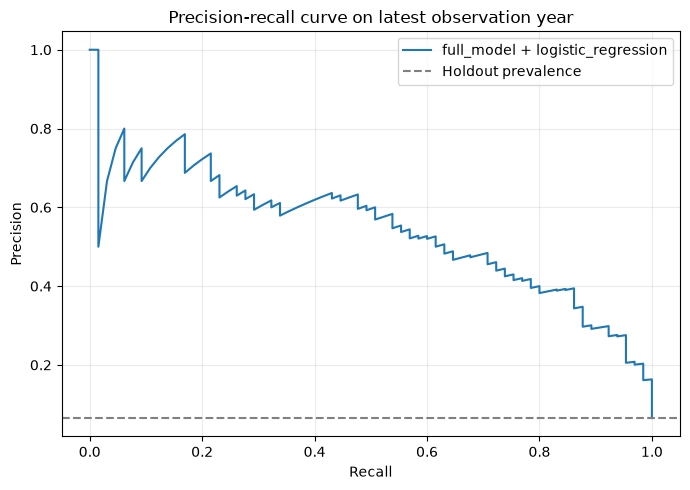

Artifacts saved under c:\Users\msdor\donor_prediction_capstone_project\outputs


In [8]:
from sklearn.metrics import precision_recall_curve
precision, recall, _ = precision_recall_curve(test[TARGET], selected_probability)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"{selected['feature_set']} + {selected['model']}")
plt.axhline(test[TARGET].mean(), linestyle='--', color='gray', label='Holdout prevalence')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-recall curve on latest observation year')
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUTS / 'feature_report_precision_recall.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Artifacts saved under {OUTPUTS}')

## 7. Five-fold out-of-fold baseline regression

This baseline is a class-balanced logistic regression using the recent-giving feature set. Each training row receives a prediction from a model that did not see that row during fitting. The resulting out-of-fold (OOF) predictions are the validation test for the baseline; the latest observation year remains a separate time holdout.

In [9]:
from sklearn.model_selection import StratifiedKFold

baseline_features = feature_sets['recent_giving_baseline']
X_baseline = train[baseline_features].reset_index(drop=True)
y_baseline = train[TARGET].reset_index(drop=True)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_predictions_by_model = {}
oof_fold = np.full(len(train), -1, dtype=int)

model_factories_oof = {
    'logistic_regression': lambda: LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'random_forest': lambda: RandomForestClassifier(n_estimators=250, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
    'gradient_boosting': lambda: GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE),
}
for fold, (fit_idx, valid_idx) in enumerate(folds.split(X_baseline, y_baseline), start=1):
    oof_fold[valid_idx] = fold
    for model_name, factory in model_factories_oof.items():
        fold_pipeline = make_pipeline(baseline_features, factory())
        fold_pipeline.fit(X_baseline.iloc[fit_idx], y_baseline.iloc[fit_idx])
        if model_name not in oof_predictions_by_model:
            oof_predictions_by_model[model_name] = np.full(len(train), np.nan)
        oof_predictions_by_model[model_name][valid_idx] = fold_pipeline.predict_proba(X_baseline.iloc[valid_idx])[:, 1]

assert (oof_fold >= 1).all()
comparison_rows = []
oof_prediction_frames = []
for model_name, probabilities in oof_predictions_by_model.items():
    assert np.isfinite(probabilities).all()
    comparison_rows.append({
        'model': model_name,
        'folds': 5,
        'rows': len(y_baseline),
        'average_precision_oof': average_precision_score(y_baseline, probabilities),
        'roc_auc_oof': roc_auc_score(y_baseline, probabilities),
        'brier_score_oof': brier_score_loss(y_baseline, probabilities),
    })
    oof_prediction_frames.append(pd.DataFrame({
        'constituent_id': train['constituent_id'].to_numpy(),
        'observation_fiscal_year': train['fiscal_year'].to_numpy(),
        'actual': y_baseline.to_numpy(), 'fold': oof_fold,
        'model': model_name, 'predicted_probability_oof': probabilities,
    }))
baseline_oof_metrics = pd.DataFrame(comparison_rows).sort_values(
    ['average_precision_oof', 'roc_auc_oof', 'brier_score_oof'], ascending=[False, False, True]
).reset_index(drop=True)
baseline_oof_predictions = pd.concat(oof_prediction_frames, ignore_index=True)
baseline_oof_metrics.to_csv(OUTPUTS / 'baseline_5fold_oof_model_comparison.csv', index=False)
baseline_oof_predictions.to_csv(OUTPUTS / 'baseline_5fold_oof_predictions.csv', index=False)
display(baseline_oof_metrics.style.format({
    'average_precision_oof': '{:.4f}', 'roc_auc_oof': '{:.4f}', 'brier_score_oof': '{:.4f}'
}))
display(baseline_oof_predictions.head())

,model,folds,rows,average_precision_oof,roc_auc_oof,brier_score_oof
0,gradient_boosting,5,3000,0.1229,0.7589,0.0333
1,random_forest,5,3000,0.1114,0.7408,0.1424
2,logistic_regression,5,3000,0.1104,0.7610,0.1796


,constituent_id,observation_fiscal_year,actual,fold,model,predicted_probability_oof
0,S00104067,2022,0,1,logistic_regression,0.450063
1,S00078686,2022,0,3,logistic_regression,0.289983
2,S00013646,2022,0,5,logistic_regression,0.845589
3,S00019424,2022,0,4,logistic_regression,0.304849
4,S00097775,2022,1,4,logistic_regression,0.451491


In [10]:
fold_metrics = []
for model_name, probabilities in oof_predictions_by_model.items():
    for fold in range(1, 6):
        mask = oof_fold == fold
        fold_metrics.append({
            'model': model_name, 'fold': fold, 'rows': int(mask.sum()),
            'average_precision': average_precision_score(y_baseline[mask], probabilities[mask]),
            'roc_auc': roc_auc_score(y_baseline[mask], probabilities[mask]),
            'brier_score': brier_score_loss(y_baseline[mask], probabilities[mask]),
        })
fold_metrics = pd.DataFrame(fold_metrics)
fold_metrics.to_csv(OUTPUTS / 'baseline_5fold_oof_fold_metrics.csv', index=False)
display(fold_metrics.style.format({
    'average_precision': '{:.4f}', 'roc_auc': '{:.4f}', 'brier_score': '{:.4f}'
}))
print('All three models use identical folds and each OOF prediction excludes its validation row.')

,model,fold,rows,average_precision,roc_auc,brier_score
0,logistic_regression,1,600,0.1529,0.7946,0.1791
1,logistic_regression,2,600,0.1325,0.8052,0.1797
2,logistic_regression,3,600,0.1210,0.7339,0.1695
3,logistic_regression,4,600,0.1363,0.8044,0.1804
4,logistic_regression,5,600,0.0835,0.6861,0.1895
5,random_forest,1,600,0.1571,0.8367,0.1309
6,random_forest,2,600,0.1390,0.7432,0.1399
7,random_forest,3,600,0.1082,0.6881,0.1431
8,random_forest,4,600,0.1297,0.7816,0.1449
9,random_forest,5,600,0.0990,0.6906,0.1529


All three models use identical folds and each OOF prediction excludes its validation row.


## Interpretation checklist

The comparison table is a predictive benchmark, not a causal analysis. Before using this workflow with production data, confirm the recognition rule, historical availability of snapshot attributes, spouse-grouped validation requirements, and row-removal counts for every cleaning rule. Feature importance should be described as model-specific association.